In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

from sys import path
path.append("src")

from signal_generation import generate_qpsk

print("Libraries and QPSK generator loaded successfully!")

BPSK generated: 1000
QPSK generated: 1000
16-QAM generated: 1000
Libraries and QPSK generator loaded successfully!


In [2]:
def generate_rayleigh_channel(n_samples):

    h_real = np.random.randn(n_samples)
    h_imag = np.random.randn(n_samples)

    h = (h_real + 1j * h_imag) / np.sqrt(2)

    return h

In [3]:
h = generate_rayleigh_channel(10000)

print("Average channel power:", np.mean(np.abs(h)**2))
print("Average channel amplitude:", np.mean(np.abs(h)))

Average channel power: 1.005962874845449
Average channel amplitude: 0.8879009056355422


In [4]:
def apply_rayleigh_fading(signal):

    # One complex fading coefficient per sensing window
    h = generate_rayleigh_channel(1)[0]

    # Apply fading to the transmitted signal
    faded_signal = h * signal

    return faded_signal, h

In [5]:
# Generate QPSK signal
qpsk = generate_qpsk(10000)

# Apply Rayleigh fading
faded_signal, h = apply_rayleigh_fading(qpsk)

print("Channel coefficient:", h)
print("Channel amplitude:", np.abs(h))
print("Channel power:", np.abs(h)**2)

print("\nOriginal signal power:",
      np.mean(np.abs(qpsk)**2))

print("Faded signal power:",
      np.mean(np.abs(faded_signal)**2))

Channel coefficient: (0.47556443557179345-0.4627848931143442j)
Channel amplitude: 0.6635747054217583
Channel power: 0.44033138967557334

Original signal power: 1.0
Faded signal power: 0.4403313896755732


In [6]:
original_power = np.mean(np.abs(qpsk)**2)
faded_power = np.mean(np.abs(faded_signal)**2)

expected_faded_power = np.abs(h)**2 * original_power

print("Measured faded power:", faded_power)
print("Expected faded power:", expected_faded_power)

print(
    "Verification:",
    np.isclose(faded_power, expected_faded_power)
)

Measured faded power: 0.4403313896755732
Expected faded power: 0.44033138967557334
Verification: True


In [7]:
def add_awgn_to_signal(signal, snr_db):

    signal_power = np.mean(np.abs(signal)**2)

    snr_linear = 10**(snr_db / 10)

    noise_power = signal_power / snr_linear

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(len(signal)) +
        1j * np.random.randn(len(signal))
    )

    received_signal = signal + noise

    return received_signal, noise

In [8]:
# Generate a fresh QPSK signal
qpsk = generate_qpsk(10000)

# Apply Rayleigh fading
faded_signal, h = apply_rayleigh_fading(qpsk)

# Add AWGN at 10 dB SNR
received_signal, noise = add_awgn_to_signal(
    faded_signal, 10
)

print("Rayleigh channel coefficient:", h)

print("Original signal power:",
      np.mean(np.abs(qpsk)**2))

print("Faded signal power:",
      np.mean(np.abs(faded_signal)**2))

print("Received signal power:",
      np.mean(np.abs(received_signal)**2))

print("Noise power:",
      np.mean(np.abs(noise)**2))

Rayleigh channel coefficient: (0.07510694759832937-1.486121123241537j)
Original signal power: 1.0
Faded signal power: 2.2141970465222265
Received signal power: 2.4360685018812442
Noise power: 0.22271438498327953


In [9]:
measured_snr = 10 * np.log10(
    np.mean(np.abs(faded_signal)**2) /
    np.mean(np.abs(noise)**2)
)

print("Target SNR: 10 dB")
print(f"Measured SNR: {measured_snr:.2f} dB")

Target SNR: 10 dB
Measured SNR: 9.97 dB


In [10]:
# Generate QPSK signal
qpsk = generate_qpsk(10000)

# Case 1: AWGN only
awgn_received, _ = add_awgn_to_signal(qpsk, 10)

# Case 2: Rayleigh fading + AWGN
faded_signal, h = apply_rayleigh_fading(qpsk)

rayleigh_received, _ = add_awgn_to_signal(
    faded_signal, 10
)

print("Rayleigh coefficient:", h)

Rayleigh coefficient: (-1.174669108906192+0.26179386676027466j)


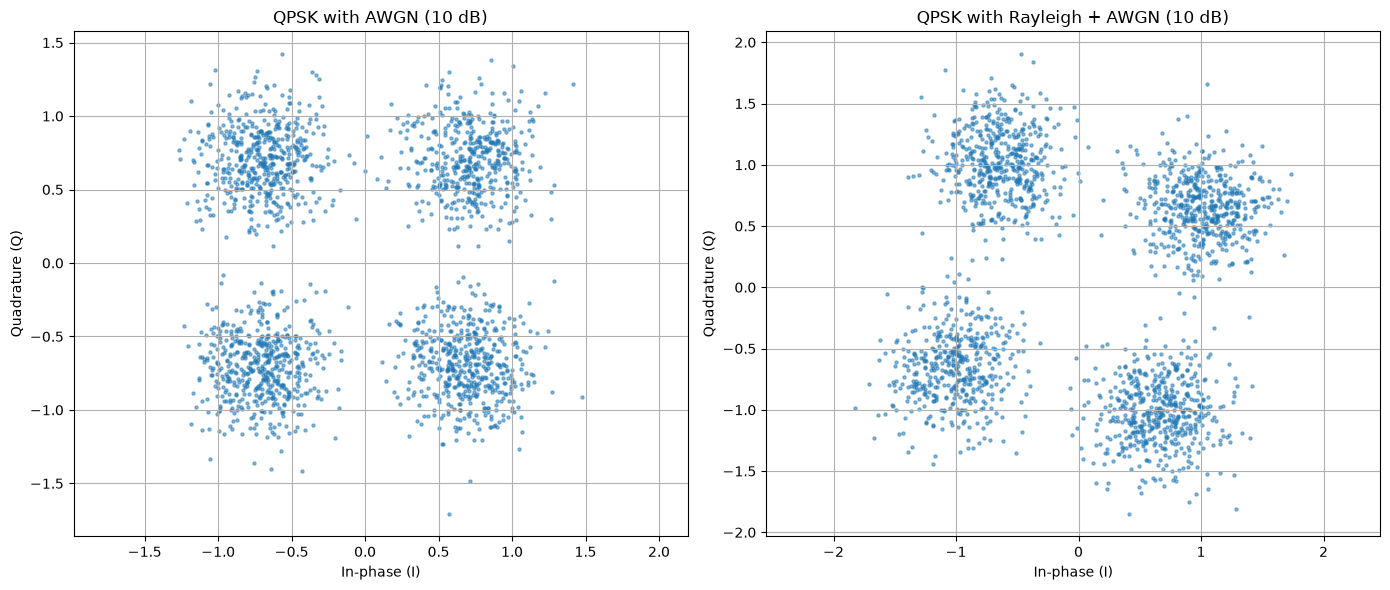

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# AWGN-only constellation
axes[0].scatter(
    awgn_received[:2000].real,
    awgn_received[:2000].imag,
    s=5,
    alpha=0.5
)

axes[0].set_title("QPSK with AWGN (10 dB)")
axes[0].set_xlabel("In-phase (I)")
axes[0].set_ylabel("Quadrature (Q)")
axes[0].grid(True)
axes[0].axis("equal")

# Rayleigh + AWGN constellation
axes[1].scatter(
    rayleigh_received[:2000].real,
    rayleigh_received[:2000].imag,
    s=5,
    alpha=0.5
)

axes[1].set_title("QPSK with Rayleigh + AWGN (10 dB)")
axes[1].set_xlabel("In-phase (I)")
axes[1].set_ylabel("Quadrature (Q)")
axes[1].grid(True)
axes[1].axis("equal")

plt.tight_layout()
plt.show()